# Result Annotation
- first approach:

- reducing max-frequency for the dft 5000: since the high frequency has low diffrence between anomalyies and nominality

mean difference:
(72, 58, 42, 28)
Accuracy: 0.65
Precision: 0.63
Recall: 0.72
F1-Score: 0.67
- data normalization:


- reducing at 4000:
mean difference:
(69, 56, 44, 31)
Accuracy: 0.62
Precision: 0.61
Recall: 0.69
F1-Score: 0.65

- 1000-5000hz
(66, 65, 35, 34)
Accuracy: 0.66
Precision: 0.65
Recall: 0.66
F1-Score: 0.66
- keeping some training data for validation (understanding how much anomalies determine an anomalous sample):

  - mean square predictor:
(62, 67, 33, 38)
Accuracy: 0.65
Precision: 0.65
Recall: 0.62
F1-Score: 0.64

  -isolation forest:
  (43, 50, 50, 57)
Accuracy: 0.47
Precision: 0.46
Recall: 0.43
F1-Score: 0.45


### NOTE
i'm aware that the feature passed to the autoencoder are not normalized but i have noticed a better score in this way using the mse, evaluation approach.
while fore the isolation forest on the latent space i normalized the latent space feature instead of the input

# Progetto Digital Forensic
## Campagnaro Matteo Matricola: 2155351

### Dataset:

### Dataset Info:
The data consists of the normal/anomalous operating sounds of seven types of real/toy machines:


1.   Fan
2.   Gearbox
3.   Pump
4.   Slide Rail
5.   Valve

Each sond is then divided in three section and each section is a complete set of training and test data.

Each section is compose of a training set of 1000 normal sample and a test set of 100 normal sample and 100 anomaly sample.
## Task:

Train a model that's able to distinguish the anomly sound from the normal one.


# Import the dataset from the drive

In [1]:
from google.colab import drive
drive.mount('/content/drive')

#decompress the dataset
!7z x drive/MyDrive/dataset/source_test.zip
!7z x drive/MyDrive/dataset/train.zip

Mounted at /content/drive

7-Zip [64] 16.02 : Copyright (c) 1999-2016 Igor Pavlov : 2016-05-21
p7zip Version 16.02 (locale=en_US.UTF-8,Utf16=on,HugeFiles=on,64 bits,2 CPUs Intel(R) Xeon(R) CPU @ 2.20GHz (406F0),ASM,AES-NI)

Scanning the drive for archives:
  0M Scan         1 file, 155085393 bytes (148 MiB)

Extracting archive: drive/MyDrive/dataset/source_test.zip
--
Path = drive/MyDrive/dataset/source_test.zip
Type = zip
Physical Size = 155085393

  0%      3% 46 - source_test/section_01_source_test_anomaly_0080.wav                                                               7% 90 - source_test/section_00_source_test_normal_0088.wav                                                              9% 113 - __MACOSX/source_t

# Necessary import

In [2]:
import librosa #load wav file and mel function
import numpy as np
import os
import sys
import scipy.stats
import matplotlib.pyplot as plt
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense, BatchNormalization, Activation
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
from sklearn.metrics import roc_curve, auc # for result visualization

#Utility function
- file_to_features: return the mel spectrum of the specified audio file, (concatenate multiple frame)


- file_list_to_data: return the array containing the mel transform of the list of files passed as input and the true label name


- get_files_list: return the list off al the file in the directory passed and having in the name the section string


- separate_data: given a file list it return the anomalies list and the normal one


-aplit_data: divide randomly the data in the percentage passed as parameter

In [3]:
def file_to_features(file_name,
                    n_mels=64,
                    n_frames=5,
                    n_fft=1024,
                    hop_length=512,
                    power=2.0,
                    f_min=1000,
                    f_max=5000):
    # generate melspectrogram using librosa
    y, sr = librosa.load(file_name, sr=None, mono=True)#none
    mel_spectrogram = librosa.feature.melspectrogram(y=y,
                                                     sr=sr,
                                                     n_fft=n_fft,
                                                     hop_length=hop_length,
                                                     n_mels=n_mels,
                                                     power=power,
                                                     fmin=f_min,
                                                     fmax=f_max)
    # convert melspectrogram to log mel energies
    log_mel_spectrogram = 20.0 / power * np.log10(np.maximum(mel_spectrogram, sys.float_info.epsilon))


    n_vectors = len(log_mel_spectrogram[0, :]) - n_frames + 1
    #n_mels * n_frames = concatenation of the first #(n_frames) filter: n_mels
    vectors = np.zeros((n_vectors, n_mels * n_frames))
    for t in range(n_frames):
      # now the vector rows rappresent time, the columns the sample
        vectors[:, n_mels * t : n_mels * (t + 1)] = log_mel_spectrogram[:, t : t + n_vectors].T
    return vectors

In [4]:
def file_list_to_data(file_list,
                      n_mels=64,#64
                      n_frames=5,#5
                      n_hop_frames=1,#1
                      n_fft=1024,
                      hop_length=512,#512
                      power=2.0,
                      f_min=1000,
                      f_max=5000):
    # consider the label
    y_true = np.zeros(len(file_list), dtype=int)
    for idx in range(len(file_list)):
        if "anomaly" in file_list[idx]:
            y_true[idx] = 1
        #print(f"{file_list[idx]} --> {y_true[idx]}")
        vectors = file_to_features(file_list[idx],
                                                n_mels=n_mels,
                                                n_frames=n_frames,
                                                n_fft=n_fft,
                                                hop_length=hop_length,
                                                power=power,
                                                f_min=f_min,
                                                f_max = f_max)
        vectors = vectors[: : n_hop_frames, :]
        if idx == 0:
            data = np.zeros((len(file_list) * vectors.shape[0], n_mels * n_frames), float)
        data[vectors.shape[0] * idx : vectors.shape[0] * (idx + 1), :] = vectors

    return data, y_true

In [5]:
def get_files_list(directory = "source_test", section = "section_00"):
  return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.wav') if section in f]

In [6]:
def separate_data(file_list):
  anomalies = []
  normals = []
  for idx in range(len(file_list)):
    if "anomaly" in file_list[idx]:
      anomalies.append(file_list[idx])
    else:
      normals.append(file_list[idx])
  return anomalies, normals

In [7]:
def split_data(file_list, percentage):
  num_files = len(file_list)
  num_files_subset1 = int(num_files * percentage)

  # Randomly shuffle the file list
  np.random.shuffle(file_list)

  # Split the file list into two subsets
  subset1 = file_list[:num_files_subset1]
  subset2 = file_list[num_files_subset1:]

  return subset1, subset2

# Data visualization

In [62]:
def mel_plot(file_name, f_max=5000, f_min=1000):
    y, sr = librosa.load(file_name, sr=None, mono=True)
    mel_spectrogram = librosa.feature.melspectrogram(y=y,
                                                     sr=sr,
                                                     n_fft=1024,
                                                     hop_length=512,
                                                     n_mels=64,
                                                     power=2,
                                                     fmax=f_max,
                                                     fmin=f_min)
    fig, ax = plt.subplots()
    S_dB = librosa.power_to_db(mel_spectrogram, ref=np.max)
    img = librosa.display.specshow(S_dB, x_axis='time',
                             y_axis='mel', sr=sr,
                             fmax=sr/2, ax=ax)
    fig.colorbar(img, ax=ax, format='%+2.0f dB')
    ax.set(title=f"Mel-frequency spectrogram {file_name}")

In [65]:
def dft_plot(file_name, f_max=5000, f_min=1000):
    y, sr = librosa.load(file_name, sr=None, mono=True)
    dft = np.fft.fft(y)
    # Get the magnitude spectrum
    magnitude_spectrum = np.abs(dft)
    # Get the frequency bins
    frequencies = np.fft.fftfreq(len(dft), 1/sr)
    plt.figure(figsize=(10, 4))
    plt.axvline(x=f_min, color='red', linestyle='dotted', label=f'x = {f_min}')
    plt.axvline(x=f_max, color='blue', linestyle='dotted', label=f'x = {f_max}')
    plt.plot(frequencies, magnitude_spectrum)
    plt.title(f"Magnitude Spectrum of {file_name}")
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.xlim(0, sr/2)  # Limit to positive frequencies
    plt.grid(True)
    plt.show()

# Load training data, split them in training and validation

In [11]:
train_files = get_files_list("train", "section_00")
train_set, y_train = file_list_to_data(train_files)
n_vector_file = int(train_set.shape[0] / len(train_files))

print(f"Train set lenght: {len(train_files)}")
print("--------------------------------")
print(f"#vectors for each file {n_vector_file}")
print("--------------------------------")
print(f"Train set shape: {train_set.shape}")

Train set lenght: 1003
--------------------------------
#vectors for each file 309
--------------------------------
Train set shape: (309927, 320)


#Train data visualization

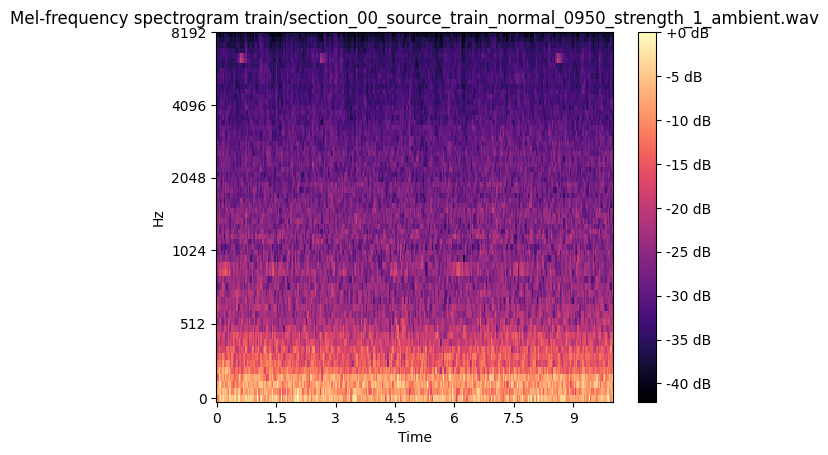

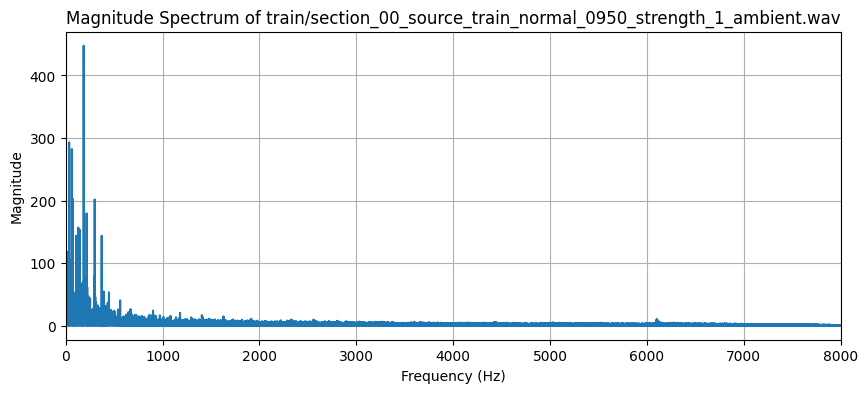

In [13]:
mel_plot(train_files[2])
dft_plot(train_files[2])

# Model definition

In [14]:
def build_autoencoder(input_dim, hidden_units, bottleneck_units, lr=0.001):
    x = Input(shape=(input_dim,))
    h = x

    for _ in range(4):  # Encoding layers
        h = Dense(hidden_units)(h)
        h = BatchNormalization()(h)
        h = Activation('relu')(h)

    h = Dense(bottleneck_units, name='bottleneck_layer')(h)
    h = BatchNormalization()(h)
    h = Activation('relu')(h)

    for _ in range(4):  # Decoding layers
        h = Dense(hidden_units)(h)
        h = BatchNormalization()(h)
        h = Activation('relu')(h)

    h = Dense(input_dim)(h)  # Output layer

    model = Model(inputs=x, outputs=h)

    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
                  loss='mean_squared_error')
    return model

# Model training

## define the parameter for the model

In [15]:
input_dim = train_set.shape[1]
bottleneck_units = 8
hidden_units = 128
epochs = 60
batch_size = 512
learning_rate = 1e-3
print(learning_rate)

0.001


## model building

In [16]:
autoencoder = build_autoencoder(input_dim, hidden_units, bottleneck_units, learning_rate)
autoencoder.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)             │ (None, 320)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          41,088 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_1 (Activation)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_2 (Activation)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bottleneck_layer (Dense)             │ (None, 8)                   │           1,032 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 8)                   │              32 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_4 (Activation)            │ (None, 8)                   │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │           1,152 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼──────────────

 Total params: 187,752 (733.41 KB)

 Trainable params: 185,688 (725.34 KB)

 Non-trainable params: 2,064 (8.06 KB)

## model training

In [17]:
autoencoder.fit(x=train_set,y=train_set, epochs=epochs, batch_size=batch_size)

Epoch 1/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - loss: 448.7023
Epoch 2/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 10.9261
Epoch 3/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - loss: 9.7136
Epoch 4/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - loss: 9.0375
Epoch 5/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - loss: 8.6924
Epoch 6/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 8.5006
Epoch 7/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 20s 32ms/step - loss: 8.3309
Epoch 8/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 18s 28ms/step - loss: 8.2062
Epoch 9/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 8.1004
Epoch 10/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 20s 28ms/step - loss: 7.9975
Epoch 11/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 17s 28ms/step - loss: 7.9204
Epoch 12/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - loss: 7.8392
Epoch 13/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 17s 27ms/step - loss: 7.7744
Epoch 14/60
606/606 ━━━━━━━━━━━━━━━━━━━━ 23s 32ms/step - loss: 7.7160
Epoch 15/60
606/606 ━━━━━━

# Anomaly detection using the mean square diff.

The prediction is based on the mean square difference between the normal sample and the reconstructed one from the autoencoder.

## Utility function

- predict: take in input the data and feed them to the autoencoder returning the mean square difference betwen the original and the reconstructed for each sample


- get_threshod: use the gamma distribution from the *scypy* to define a threshold based on the mean square difference (q) and the percentage of file that should be classified as nominality (q)

- predict_label: given the mean square difference and the threshold, label each sample as **anomaly 1** or as **nominal 0**

In [18]:
def predict(file_len, data, model, n_vectors_ea_file):
  y_pred = []
  start_idx = 0
  for file_idx in range(file_len):
    y_pred.append(np.mean(np.square(data[start_idx : start_idx + n_vectors_ea_file, :]
                  - model.predict(data[start_idx : start_idx + n_vectors_ea_file, :], verbose = 0))))
    start_idx += n_vectors_ea_file
  return y_pred

### gamma distribution
   * **`shape_hat`**: The estimated shape parameter (α) of the Gamma distribution.

   * **`loc_hat`**: The estimated location parameter (β) of the Gamma distribution.

   * **`scale_hat`**: The estimated scale parameter of the Gamma distribution.

   * The function **finds the threshold** such that the probability of a random variable from the Gamma distribution being less than or equal to the threshold is equal to `q`.
   
### Label legend
0 - normal

1 - anomaly

In [19]:
def get_threshold(y,q = 0.80):
    shape_hat, loc_hat, scale_hat = scipy.stats.gamma.fit(y)
    return scipy.stats.gamma.ppf(q=q, a=shape_hat, loc=loc_hat, scale=scale_hat)

In [20]:
def predict_label(y_pred,threshold):
    y_label = []
    for y in y_pred:
      if y > threshold:
        y_label.append(1)
      else:
        y_label.append(0)
    return y_label

## Prediction

In [22]:
y_train_pred  = predict(len(train_files), train_set, autoencoder, n_vector_file)

### labeling the data

In [23]:
threshold = get_threshold(y_train_pred)
train_pred_label = predict_label(y_train_pred, threshold)

## Result visualization

### Utility function
- measure: given the true label and the predicted one, it will evaluate TP, TN, FP, FN


- visulize result: will calculate the **accuracy, precision, recall, f1-score** and it will plot the **roc-curve, confusion metrix**

In [24]:
def measure(y_true, y_pred):
    # Initialize counts
    TP = TN = FP = FN = 0

    # Loop through true and predicted values to calculate counts
    for true, pred in zip(y_true, y_pred):
        if true == 1 and pred == 1:
            TP += 1  # True Positive
        elif true == 0 and pred == 0:
            TN += 1  # True Negative
        elif true == 1 and pred == 0:
            FN += 1  # False Negative
        elif true == 0 and pred == 1:
            FP += 1  # False Positive
    return TP, TN, FP, FN


def visualize_result(y_true, y_pred):
    # Calculate the metrics
    print(measure(y_true,y_pred))
    TP, TN, FP, FN = measure(y_true,y_pred)
    accuracy = (TP + TN) / (TP + TN + FP + FN)
    precision = TP / (TP + FP)
    recall = TP / (TP + FN)
    f1_score = 2 * (precision * recall) / (precision + recall)

    print(f"Accuracy: {accuracy:.2f}")
    print(f"Precision: {precision:.2f}")
    print(f"Recall: {recall:.2f}")
    print(f"F1-Score: {f1_score:.2f}")

    # Confusion Matrix
    cm = np.array([[TN, FP], [FN, TP]])
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.matshow(cm, cmap='Blues', alpha=0.7)
    for (i, j), value in np.ndenumerate(cm):
        ax.text(j, i, value, ha='center', va='center', color='red', fontsize=14)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['Negative', 'Positive'])
    ax.set_yticklabels(['Negative', 'Positive'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    plt.title('Confusion Matrix', fontsize=16)
    plt.show()

    # ROC Curve (For demonstration, use random values for fpr, tpr)
    # In practice, you would use `roc_curve` from your model's probabilities.
    fpr, tpr, thresholds = roc_curve(y_true, y_pred)
    roc_auc = auc(fpr, tpr)

    # Plot the ROC curve
    plt.figure(figsize=(8, 6))
    plt.plot(fpr, tpr, color='blue', label=f'ROC curve (area = {roc_auc:.2f})')
    plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('Receiver Operating Characteristic (ROC) Curve', fontsize=16)
    plt.legend(loc='lower right')
    plt.show()

### Metrics on the training set and on the validation set

In [25]:
print(f"train TP, TN, FP, FN\n     {measure(y_train, train_pred_label)}\n")

train TP, TN, FP, FN
     (0, 719, 284, 0)



## Test on the test set

### Get the test set samples

In [51]:
test_val_files = get_files_list("source_test", "section_00")
test_val_set, y_test_val = file_list_to_data(test_val_files)
anomaly_files, normal_files = separate_data(test_val_files)
val_files, _ = split_data(normal_files,0.1)
test_files = list(set(test_val_files) - set(val_files))
test_set, y_test = file_list_to_data(test_files)
val_set, y_val = file_list_to_data(val_files)

In [52]:
print(f"test shape {test_set.shape}")
print(f"test label: {y_test}, lenght {len(y_test)}")
print(20*"-")
print(f"val shape {val_set.shape}")
print(f"val label: {y_val}, lenght {len(y_val)}")

test shape (58710, 320)
test label: [0 1 1 0 1 1 0 1 0 0 1 1 0 1 1 0 1 1 1 1 1 1 1 0 0 0 1 0 1 0 1 1 0 0 0 1 1
 0 0 1 1 0 0 0 1 0 0 0 0 1 0 1 1 0 0 1 0 0 1 0 0 1 0 1 0 0 0 0 1 0 1 1 0 0
 1 1 0 0 0 1 0 1 0 1 1 0 0 1 1 1 0 0 1 0 1 0 1 0 1 0 0 1 0 0 1 1 1 0 0 1 0
 0 1 0 0 1 0 0 1 1 0 0 1 1 1 1 0 0 1 1 1 0 0 1 0 1 0 1 1 0 1 0 1 0 1 0 1 0
 0 1 0 1 1 1 1 0 1 0 1 1 0 1 1 0 1 1 0 1 0 1 0 1 0 1 1 0 1 1 1 1 0 0 1 1 1
 0 1 1 1 1], lenght 190
--------------------
val shape (3090, 320)
val label: [0 0 0 0 0 0 0 0 0 0], lenght 10


# visualize

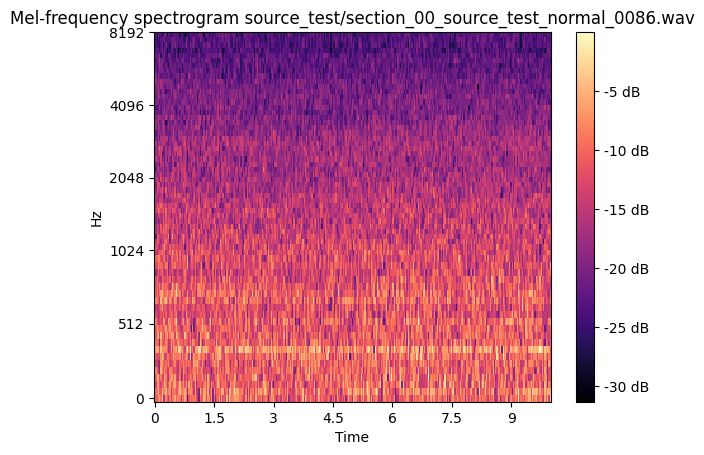

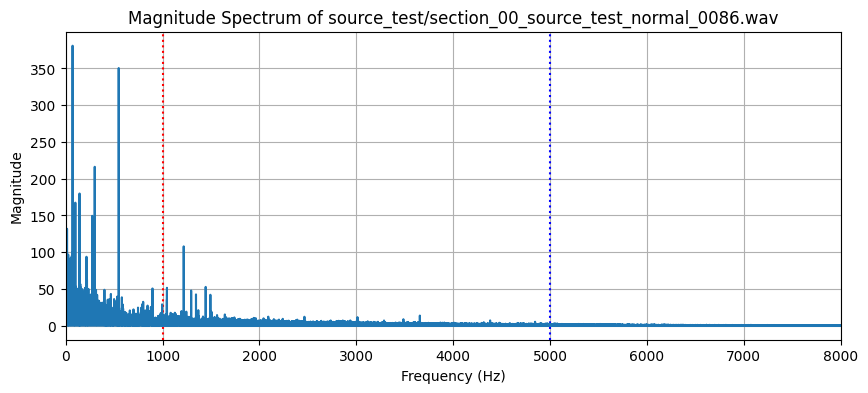

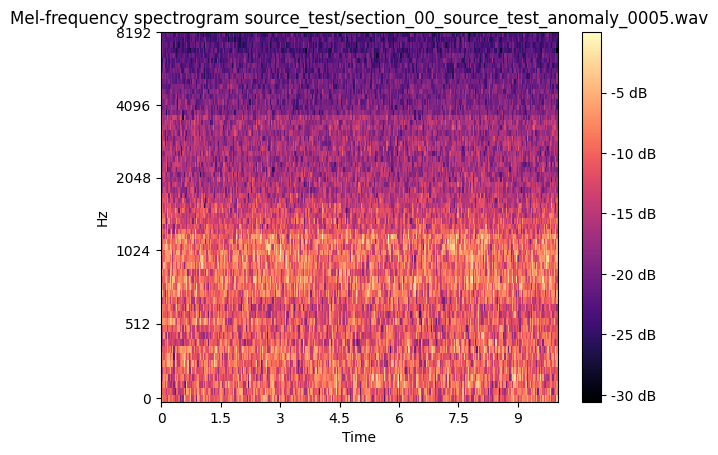

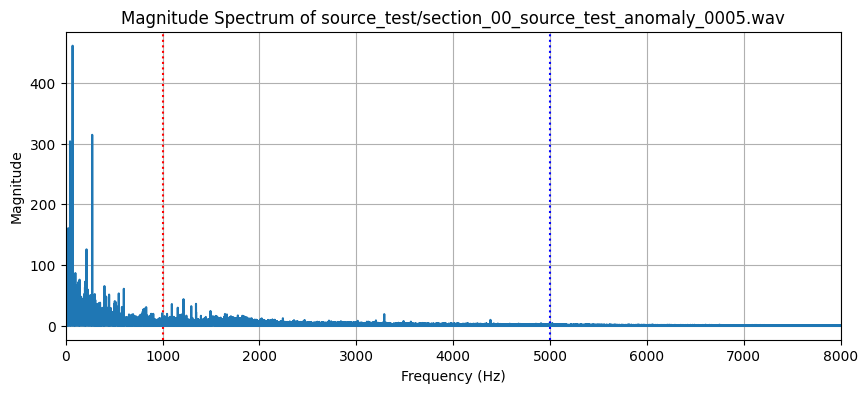

In [66]:
mel_plot(normal_files[7])
dft_plot(normal_files[7])
mel_plot(anomaly_files[7])
dft_plot(anomaly_files[7])

### Estimate the label for the test set

In [53]:
data_pred_test = predict(len(test_val_files), test_val_set, autoencoder, n_vector_file)
data_label_test = predict_label(data_pred_test, threshold)

### Visualize the result

(72, 57, 43, 28)
Accuracy: 0.65
Precision: 0.63
Recall: 0.72
F1-Score: 0.67


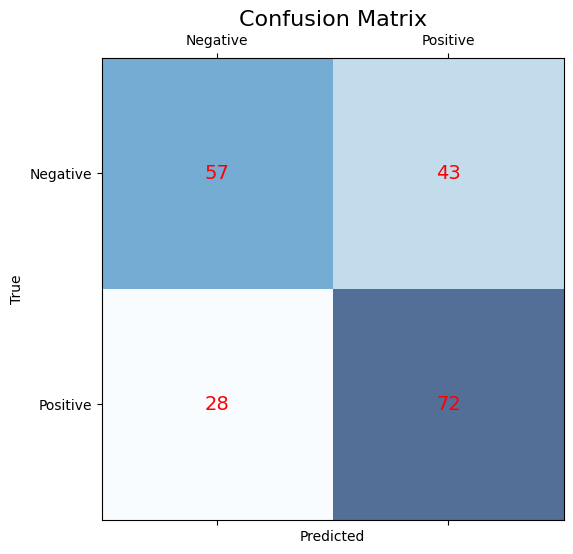

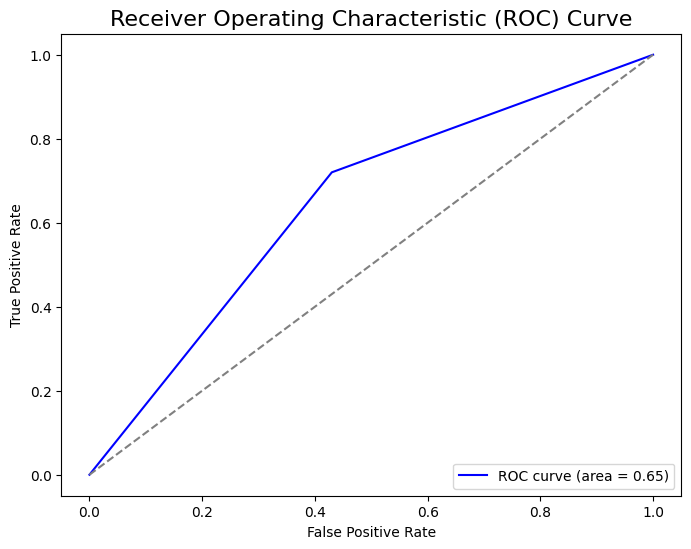

In [55]:
visualize_result(y_test_val, data_label_test)

# Anomaly detection with isolation forest

- The idea is to apply the isolation forest to the bottleneck layer of the autoencoder to evaluate if a sample is an anomaly or a normal sample.

- The problem is that, the autoencoder is build to predict singular time frame for each sample and not the entire one.

- As a solution, the isolation forest is applied on the bottlneck layer to evaluate each time frame, then using the validation set we are going to define a threshold on how much anomalous time frame are needed for a sample to define it as an anomaly

## Utility function

- fit: givven a data set in input it will return a sklearn, standard scaler fitted on the inpit

- transform: givven a data set and a sklearn, standard scaler, it will transform the data set using the sclaer passed, assuming that the scaler has already been fitted

- adapt_label: givven a vector, it will return a the same vector changing thhe 1 in zeros and the other to 1 (this is done to adapt the labels of the isolation forest to our labels)

- mean_ones: givven a vector of shape (idx, values) it will build a vector of size(idx) were for each cell it contains the number of one between the valus corresponding to that index, and then it will return the mean of the builded array

- evaluate_series:

-

In [37]:
from sklearn.preprocessing import StandardScaler
def fit(X):
  scaler = StandardScaler()
  scaler.fit(X)
  return scaler

In [38]:
def transform(X, scaler):
  return scaler.transform(X)

In [39]:
def adapt_labels(labels):
  for idx in range(len(labels)):
    if(labels[idx] == 1): #-1 non anomalies
      labels[idx] = 0
    else:
      labels[idx] = 1
  return labels

In [40]:
#count the mean number of ones in the label for each file
def mean_ones(datas_labels, n_files):
  k = int(len(datas_labels) / n_files)
  n_ones = np.zeros(n_files, dtype = int)
  for idx in range(n_files):
    n_ones[idx] = np.count_nonzero(datas_labels[idx * k: (idx + 1) * k])
  print(n_ones)
  return np.mean(n_ones)

In [41]:
# given all the label of a file it will evaluate if it's an anomaly or not
def evaluate_series(data_label, n_files, anomly_ones = 5):
  # Length of the array
    n = len(data_label)
    k = int(n / n_files)
    # Ensure n is divisible by k
    if n % k != 0:
        raise ValueError("Array length n must be divisible by k")

    # New array to store the result
    result = np.zeros(n_files, dtype = int)

    # Iterate through each frame
    for i in range(n_files):
        # Get the current frame
        frame = data_label[i * k: (i + 1) * k]

        # Count zeros and ones in the frame
        zeros = np.sum(frame == 0)
        ones = k - zeros  # Since all elements are 0 or 1

        # If there are more zeros than ones, mark as 1 in the result array
        if ones > anomly_ones:
            result[i] = 1
        else:
            result[i] = 0

    return result

## Extracting the bottlneck layer from the autoencoder

In [42]:
bottleneck_model = Model(inputs=autoencoder.input, outputs=autoencoder.get_layer('bottleneck_layer').output)  # Replace 'bottleneck_layer_name' with the actual name of your bottleneck layer
bottleneck_train_features = bottleneck_model.predict(train_set)  # Extract features from nominal training data only
bottleneck_val_features = bottleneck_model.predict(val_set)
bottleneck_test_features = bottleneck_model.predict(test_set)
print(bottleneck_train_features.shape)

9686/9686 ━━━━━━━━━━━━━━━━━━━━ 17s 2ms/step
97/97 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
1835/1835 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step
(309927, 8)


In [43]:
print(bottleneck_train_features.shape)
print(bottleneck_val_features.shape)
print(bottleneck_test_features.shape)

(309927, 8)
(3090, 8)
(58710, 8)


## Fit the bottlneck layer activation

In [44]:
scaler = fit(bottleneck_train_features)
bottleneck_train_scaled = transform(bottleneck_train_features, scaler)
bottleneck_val_scaled = transform(bottleneck_val_features, scaler)
bottleneck_test_scaled = transform(bottleneck_test_features, scaler)

In [45]:
print(bottleneck_train_scaled.shape)
print(bottleneck_val_scaled.shape)
print(bottleneck_test_scaled.shape)

(309927, 8)
(3090, 8)
(58710, 8)


## Training the isolation forest

In [46]:
from sklearn.ensemble import IsolationForest
iso_forest = IsolationForest(n_estimators=10, random_state=42)
iso_forest.fit(bottleneck_train_scaled)

IsolationForest(n_estimators=10, random_state=42)

# Predict the label for the bottleneck

In [59]:
val_bottleneck_label = adapt_labels(iso_forest.predict(bottleneck_val_scaled))
test_bottleneck_label = adapt_labels(iso_forest.predict(bottleneck_test_scaled))
mean = mean_ones(val_bottleneck_label, len(val_files))
print(mean)

[ 0  0  4 45 11  0  1 33 23 23]
14.0


## Isolation forest prediction

(29, 60, 30, 71)
Accuracy: 0.47
Precision: 0.49
Recall: 0.29
F1-Score: 0.36


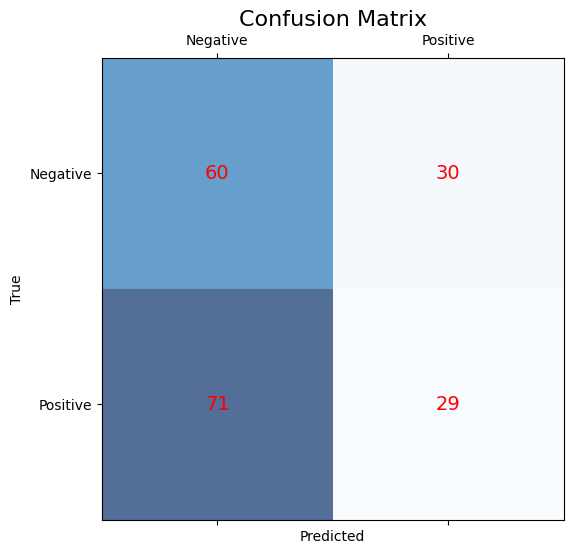

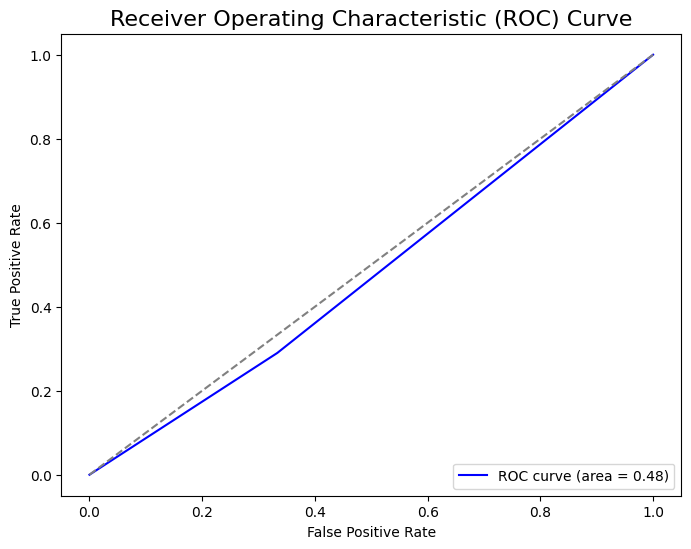

In [60]:
#data_label_test_adapt = adapt_labels(data_label_test)
#mean = mean_ones(data_label_test_adapt, n_files)* 0.7
evaluated = evaluate_series(test_bottleneck_label,len(test_files), mean)
visualize_result(y_test,evaluated)

In [49]:
autoencoder.save('my_autoencoder_model.h5')